In [1]:
import preprocess_filter
import numpy
import cv2
import matplotlib.pyplot as plt
import glob

import re
from pathlib import Path
import math

In [2]:
file_pattern = re.compile(r'.*?(\d+).*?')
def get_order(file):
    match = file_pattern.match(Path(file).name)
    if not match:
        return math.inf
    return int(match.groups()[0])

In [3]:
print(len('W1630478190_1_CALIB.rpjb'))

24


W1597976395_OC.png
1


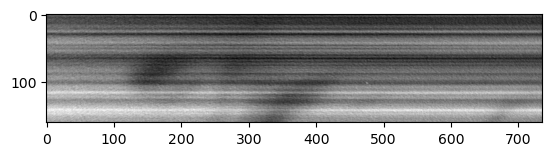

W1600557120_OC.png
2


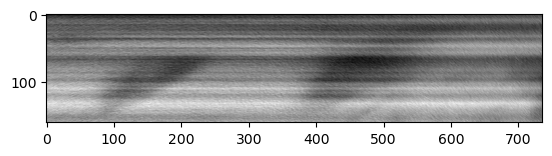

W1600569624_OC.png
3


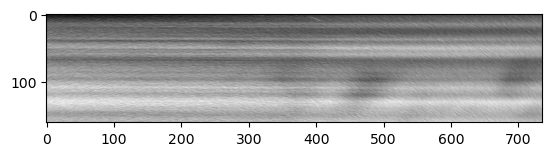

W1600571708_OC.png
4


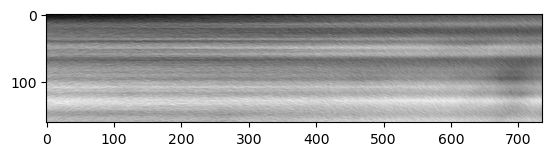

W1600580044_OC.png
5


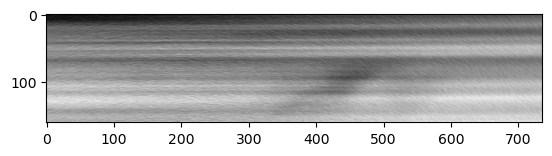

W1601177014_OC.png
6


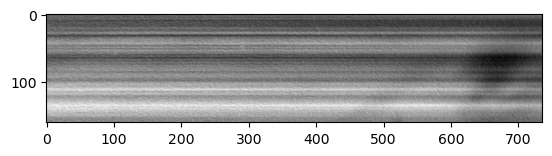

W1630455570_OC.png
7


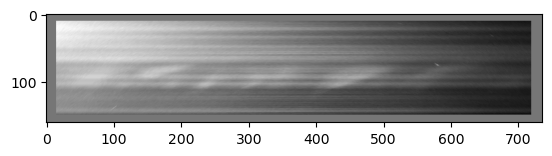

W1630478190_OC.png
8


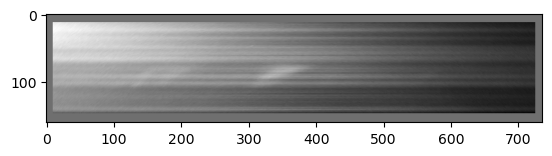

W1630481090_OC.png
9


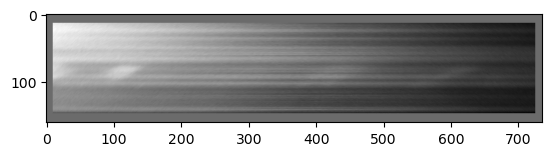

W1630492690_OC.png
10


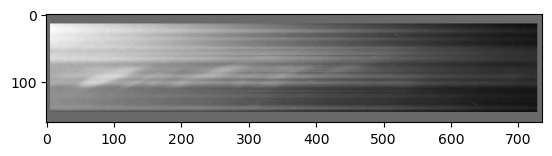

W1630501390_OC.png
11


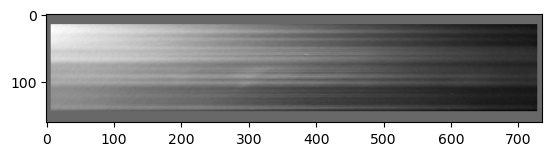

W1630507190_OC.png
12


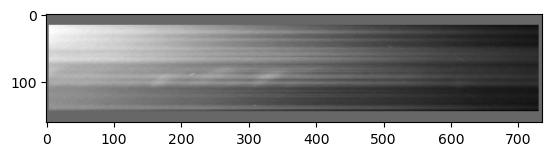

W1766475429_OC.png
13


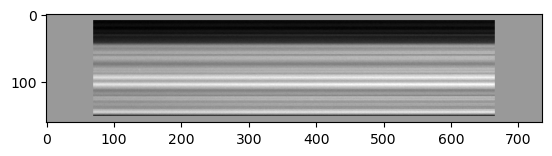

W1766507649_OC.png
14


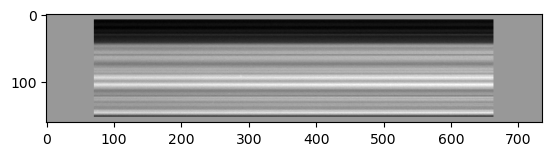

W1766550609_OC.png
15


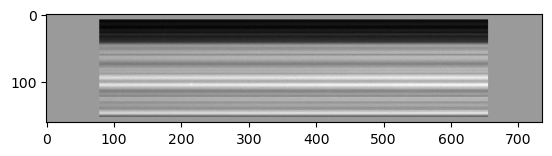

In [4]:
rpjb_list = sorted(glob.glob("../data/s3_spokes_set/rpjbs/*"), key = get_order)
new_file_path = "../data/s3_spokes_set/cropped_only/"


for rpjb_path in rpjb_list:
    filename = rpjb_path[-24:].split("_")[0] + "_OC.png"

    print(filename)
    print(rpjb_list.index(rpjb_path) + 1)

    pixel_values = preprocess_filter.apply_filters(rpjb_path)
    plt.imshow(pixel_values, cmap="gray")
    plt.show()
    preprocess_filter.save_image(new_file_path + filename, pixel_values)

In [7]:
from pathlib import Path

model_path = "models/s3_compare/fc_no_aug_spoke_15im_10e_resnet34.h5"
model_path_no_ext = str(Path(model_path).name).split('.')[0]
model_path_no_ext

'fc_no_aug_spoke_15im_10e_resnet34'

In [9]:
str(Path(model_path).parent)

'models/s3_compare'